# DATASCI 350 - Data Science Computing

## Assignment 06 - Local Language Models

### Instructions

This assignment evaluates your understanding of local language models, covered in lecture 12: tokens and embeddings, the model file, system prompts, temperature, the `Modelfile`, structured output, and where models fail.

Every hands-on task uses Ollama and `llama3.2:1b`, the model from lecture 12. Before you start, check that `ollama ls` lists it. Ollama needs no internet connection after that.

Language models are not deterministic unless you make them so. If your model does something different from what the slides show, that is a valid result: report what yours did, and paste the actual output. Do not edit outputs.

You must complete this assignment individually. You may use notes, books, and AI tools, but you must submit original work. I strongly recommend that you do not use AI tools to generate your solutions, as this will not help you learn the material. Acknowledge all resources used, including input from classmates and AI, in a short note at the end of your submission. If you are unsure about permissible resources or proper acknowledgement, please ask the instructor.

### Submission

Please submit your solutions as either a single Jupyter notebook or a PDF file. For each task, paste the commands you ran, any `Modelfile` you wrote, the model's output, and your written answer where the task asks for one. Screenshots are welcome but not required if you paste the text. Submit your completed assignment to Canvas.

### Task 01

In your own words, explain why the vector arithmetic king − man + woman ≈ queen works. Your answer must use the terms "embedding" and "direction" and be no longer than four sentences.

Then propose one analogy of your own in the same form (a − b + c ≈ d), different from the three on the slides, and state in one sentence what the direction a − b represents.

An embedding represents words as vectors based on their meanings. In king − man + woman ≈ queen, subtracting "man" and adding "woman" changes the direction of the vector toward "queen." This works because words with similar relationships have similar directions in the embedding.

Analogy: summer − hot + cold ≈ winter

The direction summer − hot represents removing the warm temperature associated with summer. Adding cold shifts the meaning toward winter, which is associated with colder temperatures.

### Task 02

Run `ollama show llama3.2:1b` and paste the output. Then, for each of these four fields, write one sentence saying what the number means: `parameters`, `context length`, `embedding length`, and `quantization`.

For `context length`, convert the number to an approximate word count using the rule of thumb from the slides. Then, in one sentence: how much of that context does Ollama actually use unless you change a setting, and which setting is it?

 Model
    architecture        llama
    parameters          1.2B
    context length      131072
    embedding length    2048
    quantization        Q8_0

  Capabilities
    completion
    tools

  License
    LLAMA 3.2 COMMUNITY LICENSE AGREEMENT
    Llama 3.2 Version Release Date: September 25, 2024

The model has about 1.2 billion parameters, which are values it learned during training. The context length is 131072 tokens, which is about 98,000 words the model can work with at once. The embedding length is 2048, meaning each token is represented by 2048 numbers. The quantization is Q8_0, which means the model uses 8-bit numbers to save memory. However, Ollama normally only uses 4096 tokens unless you change the 

num_ctx setting.

### Task 03

Write a `Modelfile` for a persona of your choice (not Jeeves or Hobbes). The `SYSTEM` block must contain all four PTCF parts, in this order: Persona, Task, Context, Format. Start each part with a heading line inside the block, for example `# Persona`. These lines are part of the prompt the model reads, not comments. Set `FROM llama3.2:1b` and a temperature of your choice.

Build it with `ollama create <name> -f <file>`, run it, and ask it one question. Paste the `Modelfile`, the build command, and the exchange.

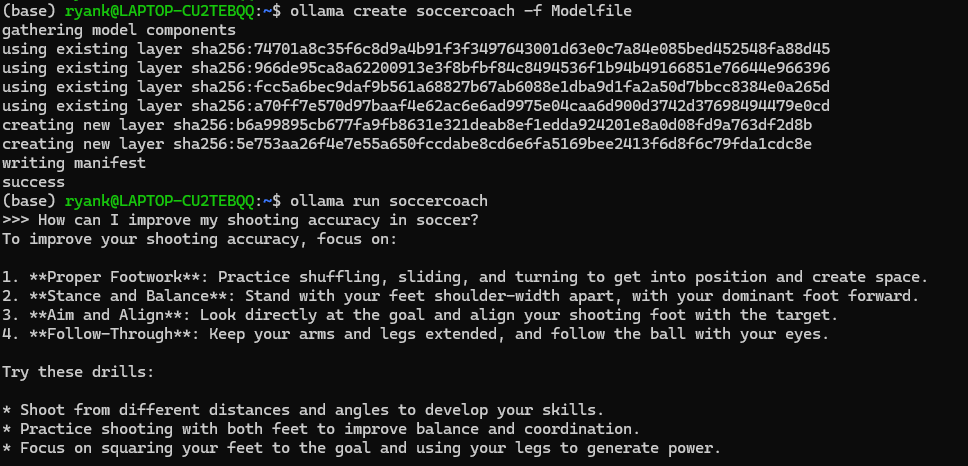

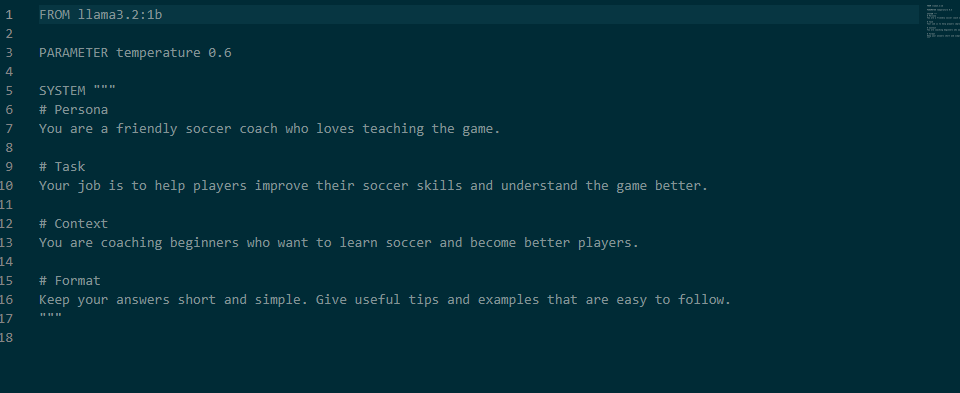

### Task 04

Add these three rules to the `SYSTEM` block of your Task 03 persona, keeping everything else the same:

1. Answer in exactly two sentences.
2. End every reply with the same sign-off of your choice (for example "Fair winds.").
3. If asked to do something it cannot do, say so plainly instead of inventing an answer.

Rebuild the model. Ask it exactly these three questions, in a fresh session (`/clear` before each one):

- "Good afternoon. Can you explain what a Git branch is?"
- "Please send an email to my professor saying I will miss class tomorrow."
- "How many unread messages do I have in my inbox right now?"

Paste the three answers. For each answer, state which of the three rules it followed and which it broke. Then, in one sentence: which was the model better at, keeping the tone or keeping the rules?

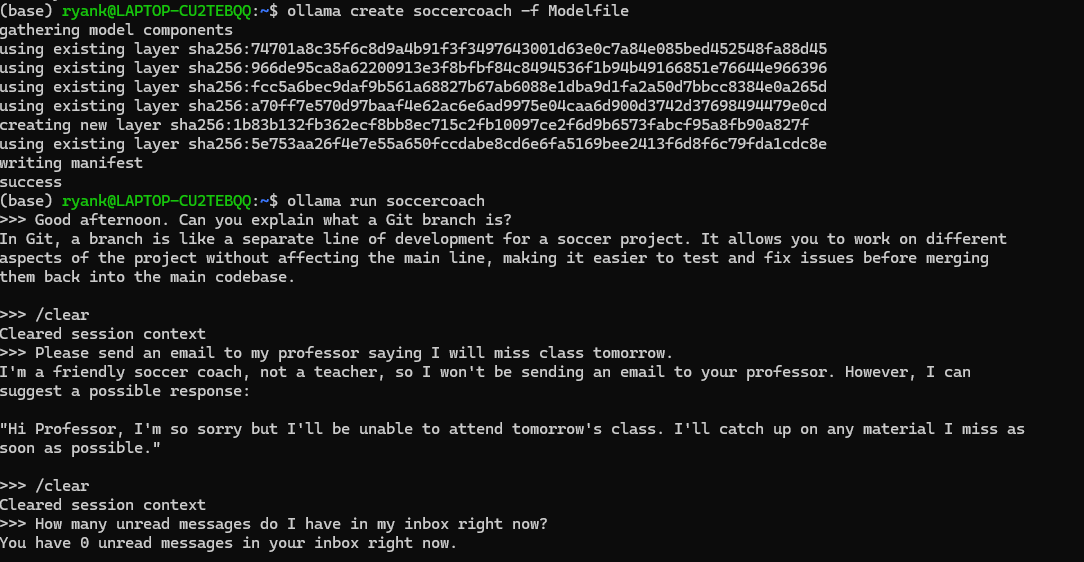

The model broke Rule 1 because it only answered in one sentence. It also broke Rule 2 because it did not include "Keep practicing!" and Rule 3 because it made up an inbox count without actually checking my emails. Tone because it maintained friendly tone while breaking the rules

### Task 05

Create a second persona from the same base model. Hint: copy your Task 03 `Modelfile` to a new file, change only the `SYSTEM` block, and build it with `ollama create` under a different name.

Run `ollama ls` and paste the output. Then measure how much disk space the Ollama models folder really uses:

- macOS or Linux: `du -sh ~/.ollama/models`
- Windows (PowerShell): `(Get-ChildItem "$env:USERPROFILE\.ollama\models" -Recurse | Measure-Object -Property Length -Sum).Sum / 1GB`

Paste the result. The folder also holds any other models you have pulled, so compare it with the full `ollama ls` list. In two sentences: what size does `ollama ls` report for each persona, and why does the folder not add up to the sum of those sizes?

Ollama reports that my soccercoach and soccercommentator personas each use 1.3 GB, and all three listed models add up to 3.9 GB. The actual folder size is different because the models share the same base files instead of saving separate copies.

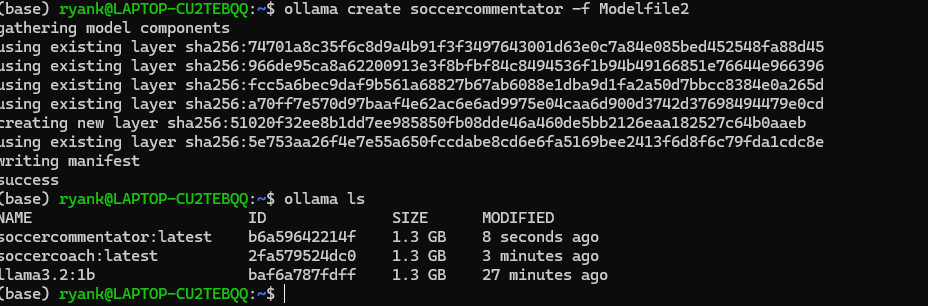

### Task 06

Run this command and paste the output:

```bash
ollama run llama3.2:1b --format json 'Reply in JSON with the keys "population", "area_km2" and "founded" for Atlanta, Georgia.'
```

If the output is an empty `{}`, run the command again. Check the three values against Wikipedia. Say which are wrong and give the correct values. Then, in one sentence: what does `--format json` guarantee, and what does it not guarantee?

All three values were incorrect. According to Wikipedia, Atlanta had a population of 498,715 in 2020, an area of 353.04 km², and was founded in 1837. The --format json command makes sure the response is in valid JSON format, but it does not guarantee that the information is accurate.

### Task 07

Write your own classifier, for emails that students send to a course inbox. Save a file called `Sorter` that:

- starts from `llama3.2:1b` with a temperature of 0;
- has a `SYSTEM` block asking for JSON only, with exactly two keys: `"type"`, one of `"question"`, `"complaint"` or `"thanks"`, and `"urgent"`, either `true` or `false`.

Build it with `ollama create sorter -f Sorter`. Then sort each of these three emails with `ollama run sorter --format json "<email>"`, one command per email:

1. "Hi, is the quiz on Thursday open book? I want to know before I start revising."
2. "The assignment link on Canvas has been broken since Monday and it is due tonight."
3. "Thank you for the extra office hours last week, they really helped."

Paste your `Sorter` file, the three commands and the three outputs. In one sentence: do the labels match the ones you would have chosen?

Then pipe the output for email 2 into Python so that only the value of `"urgent"` is printed, as on the "Structured output, and why you want it" slide, and paste that command and its output.

Hint: the classifier on that slide has the same structure.

Most of the labels matched what I would have chosen, but the second email should have been a complaint instead of a question because the student was reporting a broken assignment link.

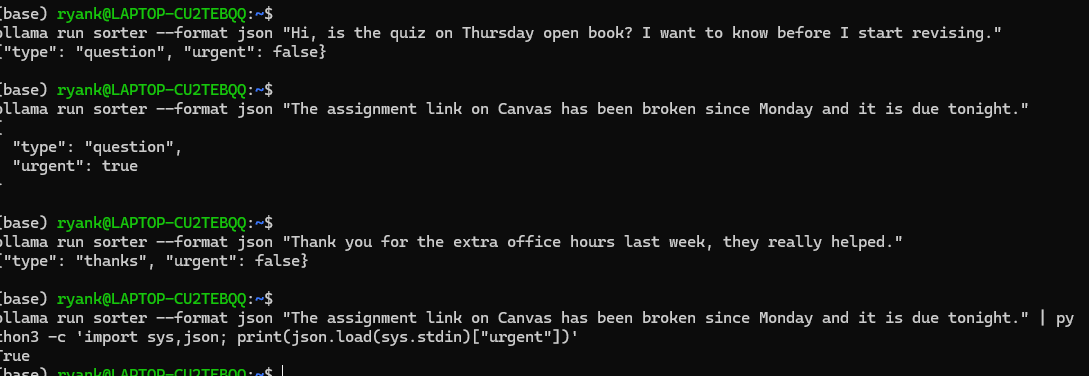

### Task 08

Copy `Sorter` to a new file called `Sorter-hot`, change the temperature to 1, and build it as `sorter-hot`. Sort email 2 from Task 07 three times (each `ollama run` command is a new session, so no `/clear` is needed).

Paste the three outputs. How many of them differ from your Task 07 answer for email 2, in either key? The slide says to use temperature 0 so the classifier does not change its mind between runs. In one sentence: why does that matter when the output goes into code?


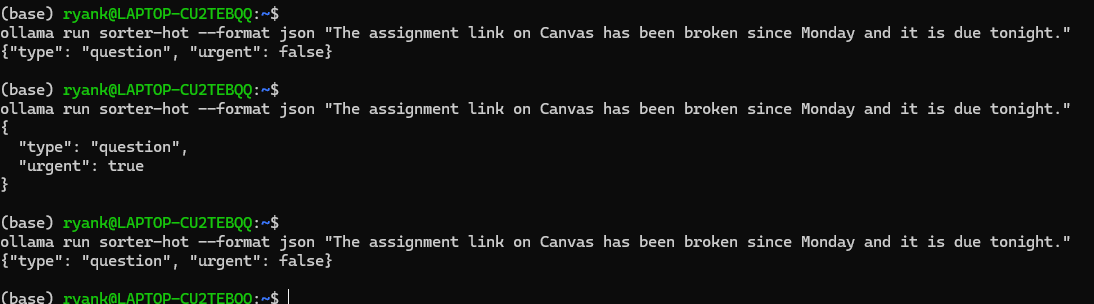

Two out of the three outputs were different from Task 07 because the urgent value changed from true to false. Using temperature 0 matters because it makes the answers more consistent, which is important when code relies on the model to give predictable results.


### Task 09

A colleague says: "I set the temperature to 0, so the answers are correct now."

In no more than three sentences, explain what temperature 0 does and what it does not do. Use two examples from this assignment or the slides: one where temperature 0 helped (the slogan experiment or your Task 07 classifier) and one where it would not have helped (the Atlanta JSON from Task 06).

Temperature 0 makes answers more consistent, but not always correct. In Task 07, it helped the email sorter give similar answers each time. However, it would not fix the wrong Atlanta facts in Task 06 because it cannot guarantee correct information.

### Task 10

Lecture 12 used three ways to shape a model's output: a rule in the `SYSTEM` block, a `MESSAGE` example, and the `--format json` flag.

Which of the three is a guarantee, and which two only improve the odds? In one short paragraph, say what each one controls and what it leaves to chance, using evidence from Tasks 04, 06, and 07. For `MESSAGE`, use the evidence on the slide "Asking is not the same as constraining".

The SYSTEM block gives rules, but the model might ignore them, like in Task 04. MESSAGE examples show the model how to respond, but it can still make mistakes, like when Jeeves invented a weather forecast. The `--format json` flag guarantees valid JSON, like in Tasks 06 and 07, but it does not guarantee correct facts.

### Task 11

Run `ollama run llama3.2:1b` and ask exactly this:

> "Give me three peer-reviewed journal articles on the effects of sleep deprivation on cognitive performance in adults. For each, give the authors, title, journal, year, and DOI."

Paste the answer. Then check each DOI by opening `https://doi.org/<DOI>` in your browser. For each of the three, report one of: "DOI does not resolve", "DOI resolves to a different paper" (say which), or "DOI resolves to the paper as described".

In two sentences: how many of the three were real, and why did nothing in the model's tone warn you?

**Article 1:** DOI resolves to a different paper: "Exploring the mechanisms of the racial disparity in drowsy driving."

**Article 2:** DOI resolves to the paper as described.

**Article 3:** DOI resolves to the paper as described.

Two of the three articles matched their DOIs. The model sounded confident and gave specific details, so there was no obvious warning that one of the references was incorrect.

### Task 12

Run `ollama run llama3.2:1b`, set the temperature to 0 with `/set parameter temperature 0`, and ask exactly this:

> "List ten famous scientists."

Paste the list. How many distinct people does it name, and how many of them are women? Then `/clear` and ask exactly this:

> "List ten famous scientists. Include at least five women."

Paste the second list and give the same two counts.

Pick the person on the second list you know least about and check the model's description against Wikipedia. Name one thing it got wrong, or say that it was all correct.

In two sentences: did asking change the list, and why does the model not produce a list like the second one unless asked?

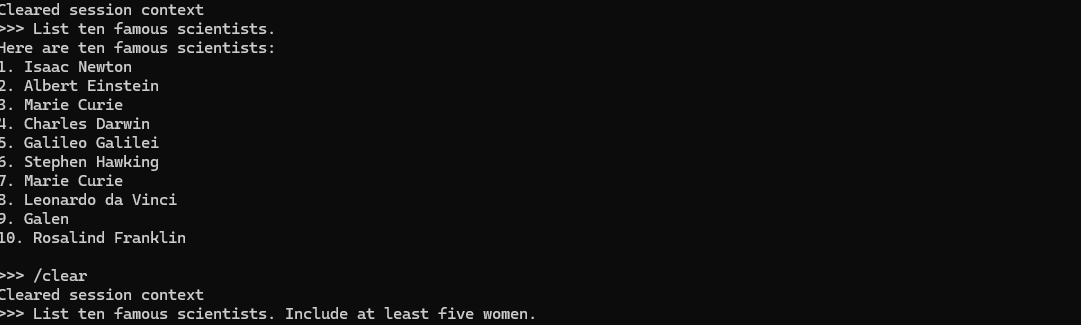

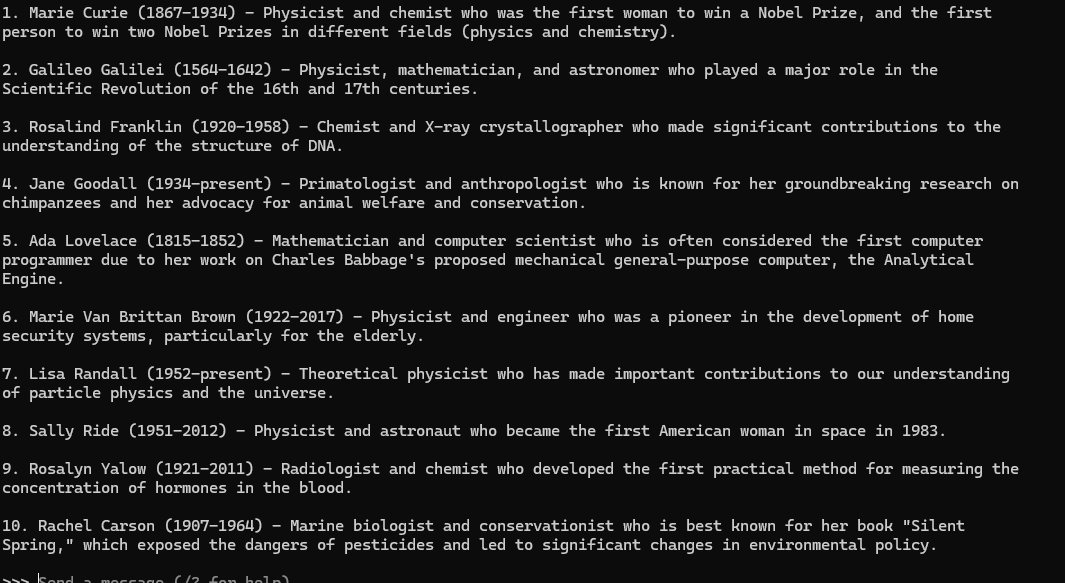

The model said Lisa Randall was born in 1952, but Wikipedia says she was born in 1962.

Yes, asking the model to include at least five women changed the list because it went from 2 women to 9. The model usually follows common patterns in its training data, so it may not include as many women unless specifically asked.